# 08 - Final Test Evaluation (Phase 7)
**This notebook is the one-time, pre-registered final evaluation.** Phases 4-6 (development evidence) are *not* revisited or rewritten here.

## Frozen decisions (recorded before the test set is opened)
| Item | Frozen value | Source |
|---|---|---|
| **Primary model** | **Logistic Regression B** (`LR_B`): CGPA, AptitudeTestScore, SoftSkillsRating, SSC_Marks, HSC_Marks standardised; Internships, Projects, Workshops/Certifications one-hot categorical; ExtracurricularActivities, PlacementTraining binary; L2, C = 1, **no class weighting** | Phase 4 `models/phase4/model_configs.json` |
| **Probabilities** | **raw**, no recalibration (Phase 5: sigmoid negligible, isotonic not helpful; no method met the materiality rule) | Phase 5 |
| **Threshold 0.50** | reference / default | Phase 4 |
| **Threshold 0.35** | *selected operating threshold under the F1-oriented criterion* (highest validation F1, ties to nearest 0.50). **Not** called "the best threshold". | Phase 6 `07_threshold_selection.json` |
| **Secondary comparators** | `GB_B` and `RF_B`, frozen Phase 4 configurations, evaluated descriptively. **No re-selection, LR_B is not replaced on test performance.** | Phase 4 |

**Rules after the test set is opened:** no model selection, threshold search, calibration selection, feature selection, hyper-parameter tuning or preprocessing change. The test set is evaluation-only.

## Phase 4/5/6 development model vs Phase 7 final model
| | Phase 4/5/6 *development* model | Phase 7 *final* model |
|---|---|---|
| Specification | frozen pipeline above | **identical** (`sklearn.clone` of the Phase 4 pipeline; parameters asserted equal) |
| Fitted on | **train** (6,938) | **train + validation** (8,425), after all decisions were frozen |
| Used for | validation results, CV, calibration, thresholds, explainability | test predictions only |

Refitting re-estimates the fitted quantities (coefficients, `StandardScaler` mean / SD) on the larger development set; no specification, preprocessing step, hyper-parameter, reference level, feature, regularisation, calibration choice or threshold changes. `OneHotEncoder(drop=[1, 3, 0])` keeps the Phase 4 reference levels explicitly.

## Test-set access history (disclosed)
Test data were not used for model development, selection, tuning, calibration, or threshold selection. Earlier exploratory notebooks (Phases 1-3) accessed the eventual test rows for descriptive analysis (data understanding and split construction, EDA, statistics); these rows were not used to fit or evaluate predictive models. Before this notebook ran, two orientation shell commands (`head -2 data/processed/test.csv` and `wc -l data/processed/*.csv`) read the processed test file outside the audit hook; neither was used for any model decision, tuning, threshold, calibration or fitting. The Phase 4-6 audit hooks describe those notebooks only. In Phase 7 the test set is intentionally accessed **once**, under the audit gate below, after the modelling protocol has been frozen.

## Test-access controls (enforced in code)
1. An audit hook **raises** on any open of the raw `test.csv`, and on any open of the processed `test.csv` unless the gate is open. The gate opens only in the cell that prints the banner, admits **exactly one** open and then raises on a second.
2. The file is read once as bytes (SHA-256 taken from those bytes), then parsed from memory.
3. A marker file `08_test_access_log.json` is written at that moment and **blocks any re-execution** that would open the test set again.
4. The frozen protocol is written to `08_frozen_protocol.json` *before* the test set is opened.
5. The notebook is executed once on the real data; the findings text is embedded afterwards by patching one markdown cell (no re-execution).

In [1]:
import warnings
warnings.simplefilter("always")
import os, sys, io, json, time, hashlib, datetime, ast, re
from pathlib import Path

DRY = os.environ.get("PHASE7_DRY_RUN") == "1"

# ---------------- TEST-SET AUDIT HOOK ----------------
_OPENED = []
GATE = {"allowed": False, "opens": 0}
def make_hook(state, opened):
    def _audit(event, args):
        if event == "open" and args and isinstance(args[0], (str, bytes, os.PathLike)):
            p = os.fsdecode(args[0]); opened.append(p); parts = [s.lower() for s in Path(p).parts]
            if os.path.basename(p).lower() == "test.csv":
                if "raw" in parts:
                    raise PermissionError(f"PHASE 7 VIOLATION: the RAW test file may never be opened ({p})")
                if not state["allowed"]:
                    raise PermissionError(f"PHASE 7 VIOLATION: test.csv opened outside the gated final-evaluation cell ({p})")
                if state["opens"] >= 1:
                    raise PermissionError(f"PHASE 7 VIOLATION: test.csv would be opened a second time ({p})")
                state["opens"] += 1
    return _audit

# unit-test the hook logic on synthetic events (no file is touched)
_st = {"allowed": False, "opens": 0}; _h = make_hook(_st, [])
def _raises(f):
    try: f()
    except PermissionError: return True
    return False
assert _raises(lambda: _h("open", ("data/raw/test.csv", "r", 0)))
assert _raises(lambda: _h("open", ("data/processed/test.csv", "rb", 0)))
_st["allowed"] = True
assert _raises(lambda: _h("open", ("data/raw/test.csv", "rb", 0)))
_h("open", ("data/processed/test.csv", "rb", 0)); assert _st["opens"] == 1
assert _raises(lambda: _h("open", ("data/processed/test.csv", "rb", 0)))
_h("open", ("data/processed/train.csv", "rb", 0))
print("audit-hook logic self-test passed (synthetic events only)")
sys.addaudithook(make_hook(GATE, _OPENED))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, sklearn
import statsmodels.api as sm
from scipy import stats
from sklearn.base import clone
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, log_loss, brier_score_loss)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC, RAW, MODELS = ROOT / "data" / "processed", ROOT / "data" / "raw", ROOT / "models" / "phase4"
if DRY:
    OUT = Path(os.environ["PHASE7_DRY_OUT"]); MET, FIG, MOD7 = OUT / "metrics", OUT / "figures", OUT / "models"
    print("*** DRY RUN: validation.csv stands in for test.csv; all outputs go to", OUT, "***")
else:
    MET, FIG, MOD7 = ROOT / "results" / "metrics" / "modeling", ROOT / "results" / "figures" / "modeling", ROOT / "models" / "phase7"
for d in (MET, FIG, MOD7): d.mkdir(parents=True, exist_ok=True)
PHASE_RESULTS = ROOT / "results" / "metrics" / "modeling"        # Phase 4-6 files: read only

SEED, B_BOOT, NB, EPS = 42, 2000, 10, 1e-12
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 60); pd.set_option("display.max_colwidth", 110)
sns.set_theme(style="whitegrid", rc={"grid.color": "#e3e6ea", "axes.edgecolor": "#9aa3ad", "axes.titlesize": 12,
                                      "axes.titleweight": "semibold", "axes.labelsize": 10.5, "figure.dpi": 110})
INK, NEUTRAL = "#1d2733", "#6b7785"
MODEL_COL = {"LR_B": "#0072B2", "GB_B": "#009E73", "RF_B": "#D55E00"}      # fixed order, colour follows the model
MODEL_NAME = {"LR_B": "Logistic regression B (primary)", "GB_B": "Gradient boosting B", "RF_B": "Random forest B"}
def savefig(fig, name):
    fig.tight_layout(); fig.savefig(FIG / f"{name}.png", dpi=200, bbox_inches="tight"); plt.show()
sha_file = lambda p: hashlib.sha256(Path(p).read_bytes()).hexdigest()
print("scikit-learn", sklearn.__version__, "| seed", SEED, "| bootstrap resamples", B_BOOT)

audit-hook logic self-test passed (synthetic events only)


scikit-learn 1.9.1 | seed 42 | bootstrap resamples 2000


## 1. Development data (TRAIN + VALIDATION only), frozen artifacts, integrity baselines

In [2]:
TARGET = "PlacementStatus"
FEATURES = ["CGPA", "Internships", "Projects", "Workshops/Certifications", "AptitudeTestScore", "SoftSkillsRating",
            "ExtracurricularActivities", "PlacementTraining", "SSC_Marks", "HSC_Marks"]
COUNT = ["Internships", "Projects", "Workshops/Certifications"]
MODEL_IDS = ["LR_B", "GB_B", "RF_B"]

# ---- integrity baselines at the START of the run (nothing below touches test.csv) ----
def snapshot():
    snap = {"processed_train": sha_file(PROC / "train.csv"), "processed_validation": sha_file(PROC / "validation.csv"),
            "processed_modeling_dataset": sha_file(PROC / "modeling_dataset.csv"),
            "raw_train": sha_file(RAW / "train.csv"), "raw_validation": sha_file(RAW / "validation.csv"),
            "model_configs.json": sha_file(MODELS / "model_configs.json")}
    for m in MODEL_IDS: snap[f"{m}.joblib"] = sha_file(MODELS / f"{m}.joblib")
    return snap
def stat_only(p):                      # os.stat does not open the file
    s = os.stat(p); return {"size": s.st_size, "mtime_ns": s.st_mtime_ns}
SNAP_START = snapshot()
TEST_STAT_START = {"processed_test": stat_only(PROC / "test.csv"), "raw_test": stat_only(RAW / "test.csv")}

# raw files must equal the Phase 1.5 downloaded originals (hash dictionary stored in notebook 02; the raw TEST file is checked by size/mtime only)
nb02 = json.loads((ROOT / "notebooks" / "02_data_quality_and_split.ipynb").read_text(encoding="utf-8"))
src02 = "\n".join("".join(c["source"]) for c in nb02["cells"] if c["cell_type"] == "code")
EXPECTED_RAW = ast.literal_eval(re.search(r"EXPECTED_SHA256\s*=\s*(\{.*?\})", src02, re.S).group(1))
assert SNAP_START["raw_train"] == EXPECTED_RAW["train"] and SNAP_START["raw_validation"] == EXPECTED_RAW["validation"]
print("raw train / validation files identical to the Phase 1.5 originals (SHA-256).")

train = pd.read_csv(PROC / "train.csv"); val = pd.read_csv(PROC / "validation.csv")
for d in (train, val):
    assert d.isna().sum().sum() == 0 and set(d[TARGET]) == {"Placed", "NotPlaced"}
split_sum = pd.read_csv(ROOT / "results" / "metrics" / "02_split_summary.csv").set_index("split")
assert len(train) == split_sum.loc["train", "rows"] and len(val) == split_sum.loc["validation", "rows"]
N_TEST_EXPECTED = int(split_sum.loc["test", "rows"])
assert not (set(map(tuple, train[FEATURES].values)) & set(map(tuple, val[FEATURES].values)))
dev = pd.concat([train, val], ignore_index=True)          # development data = train then validation
X_dev, y_dev = dev[FEATURES].copy(), (dev[TARGET] == "Placed").astype(int).to_numpy()
X_tr, y_tr = train[FEATURES].copy(), (train[TARGET] == "Placed").astype(int).to_numpy()
X_va, y_va = val[FEATURES].copy(), (val[TARGET] == "Placed").astype(int).to_numpy()
for X in (X_dev, X_tr, X_va):
    for c in COUNT: X[c] = X[c].astype(int)
print(f"development data: train {len(train):,} + validation {len(val):,} = {len(dev):,} rows (Placed rate {y_dev.mean():.4f}); expected test rows {N_TEST_EXPECTED:,}")

with open(MODELS / "model_configs.json", encoding="utf-8") as fh: P4 = json.load(fh)
thr_sel = json.loads((PHASE_RESULTS / "07_threshold_selection.json").read_text(encoding="utf-8"))
prov = json.loads((PHASE_RESULTS / "05_provisional_selection.json").read_text(encoding="utf-8"))
T_DEFAULT, T_SEL = 0.50, float(thr_sel["selected_threshold"])
assert prov["provisional_model_id"] == "LR_B" and T_SEL == 0.35 and P4["threshold"] == 0.5
THRESHOLDS = [T_DEFAULT, T_SEL]

raw train / validation files identical to the Phase 1.5 originals (SHA-256).
development data: train 6,938 + validation 1,487 = 8,425 rows (Placed rate 0.4155); expected test rows 1,487


## 2. Rebuild the frozen models: specification check, then refit on train + validation
For each of `LR_B`, `GB_B`, `RF_B`: the fitted Phase 4 pipeline is loaded, **cloned** (unfitted copy with identical parameters), and the clone's parameters are asserted equal to the Phase 4 pipeline and to `model_configs.json`.
*Specification-reproduction check:* refitting the clone on **train only** must reproduce the saved Phase 4 validation probabilities (this proves that the clone really is the Phase 4 specification and that the fit is deterministic). Only then is the clone refitted on **train + validation**. Nothing about the test set is involved so far.

In [3]:
def params_equal(a, b):
    pa, pb = a.get_params(deep=True), b.get_params(deep=True)
    if pa.keys() != pb.keys(): return False
    for k in pa:
        if k in ("memory",): continue
        va, vb = pa[k], pb[k]
        if hasattr(va, "get_params"): continue                   # nested estimators are compared through their own flattened keys
        if isinstance(va, (list, tuple)) and any(hasattr(e, "get_params") or (isinstance(e, tuple) and any(hasattr(x, "get_params") for x in e)) for e in va): continue
        if va != vb and not (va is None and vb is None): return False
    return True

p4val = pd.read_csv(PHASE_RESULTS / "05_validation_predictions.csv"); assert (p4val.y_true.to_numpy() == y_va).all()
dev_models, final_models, spec_rows = {}, {}, []
t0 = time.time()
for m in MODEL_IDS:
    dev_models[m] = joblib.load(MODELS / f"{m}.joblib")                    # Phase 4 development model (fitted on train)
    cfg = P4["models"][m]["config"]
    spec = clone(dev_models[m]); assert params_equal(spec, dev_models[m])
    mp = spec.get_params()
    for k, v in cfg.items(): assert mp[f"model__{k}"] == v, (m, k, mp[f"model__{k}"], v)
    # specification-reproduction check: clone fitted on TRAIN only reproduces the saved Phase 4 validation probabilities
    chk = clone(spec).fit(X_tr, y_tr).predict_proba(X_va)[:, 1]
    assert np.allclose(chk, p4val[m].to_numpy(), atol=1e-8), f"{m}: clone fitted on train does not reproduce Phase 4 validation probabilities"
    assert np.allclose(dev_models[m].predict_proba(X_va)[:, 1], p4val[m].to_numpy(), atol=1e-10)
    final_models[m] = clone(spec).fit(X_dev, y_dev)                         # PHASE 7 FINAL MODEL: frozen spec on train + validation
    spec_rows.append({"model": m, "config": json.dumps(cfg), "spec_equals_phase4": True, "reproduces_phase4_validation_probs": True, "n_fit": len(X_dev)})
    print(f"{m}: specification identical to Phase 4 ({cfg}); reproduction check passed; refitted on {len(X_dev):,} rows")
print(f"done in {time.time() - t0:.0f}s")

lr_final = final_models["LR_B"]; lr_dev = dev_models["LR_B"]
assert lr_final.get_params()["model__C"] == 1.0 and lr_final.get_params()["model__class_weight"] is None
assert list(lr_final.named_steps["prep"].named_transformers_["cnt"].drop) == [1, 3, 0]
sc_dev, sc_fin = lr_dev.named_steps["prep"].named_transformers_["num"], lr_final.named_steps["prep"].named_transformers_["num"]
cmp = pd.DataFrame({"feature": ["CGPA", "AptitudeTestScore", "SoftSkillsRating", "SSC_Marks", "HSC_Marks"], "mean_train_only": sc_dev.mean_, "mean_train_plus_val": sc_fin.mean_,
                    "sd_train_only": sc_dev.scale_, "sd_train_plus_val": sc_fin.scale_}).round(4)
cf = pd.DataFrame({"feature": lr_dev.named_steps["prep"].get_feature_names_out(), "coef_train_only": lr_dev.named_steps["model"].coef_[0], "coef_train_plus_val": lr_final.named_steps["model"].coef_[0]})
cf["abs_change"] = (cf.coef_train_plus_val - cf.coef_train_only).abs()
print("StandardScaler means / SDs are re-estimated on train + validation (part of 'refit the same specification'):"); display(cmp.set_index("feature"))
print(f"LR_B coefficients: max |change| from refitting on train + validation = {cf.abs_change.max():.4f} log-odds"); display(cf.round(4).set_index("feature"))

LR_B: specification identical to Phase 4 ({'C': 1.0, 'class_weight': None}); reproduction check passed; refitted on 8,425 rows


GB_B: specification identical to Phase 4 ({'n_estimators': 300, 'learning_rate': 0.05, 'max_depth': 2, 'min_samples_leaf': 1}); reproduction check passed; refitted on 8,425 rows


RF_B: specification identical to Phase 4 ({'n_estimators': 300, 'max_depth': 10, 'min_samples_leaf': 10, 'max_features': 'sqrt'}); reproduction check passed; refitted on 8,425 rows
done in 7s
StandardScaler means / SDs are re-estimated on train + validation (part of 'refit the same specification'):


,mean_train_only,mean_train_plus_val,sd_train_only,sd_train_plus_val
feature,,,,
CGPA,7.6995,7.6974,0.6378,0.6390
AptitudeTestScore,79.3233,79.3215,8.1637,8.1600
SoftSkillsRating,4.3209,4.3200,0.4134,0.4130
SSC_Marks,69.1293,69.1410,10.3607,10.4063
HSC_Marks,74.4233,74.4406,8.8927,8.9100


LR_B coefficients: max |change| from refitting on train + validation = 0.1113 log-odds


,coef_train_only,coef_train_plus_val,abs_change
feature,,,
CGPA,0.2562,0.2334,0.0229
AptitudeTestScore,0.5000,0.5014,0.0013
SoftSkillsRating,0.2803,0.2707,0.0096
SSC_Marks,0.2864,0.2574,0.0290
HSC_Marks,0.2087,0.2116,0.0030
Internships_0,0.2316,0.2006,0.0311
Internships_2,0.2260,0.1933,0.0327
Projects_0,0.5036,0.6149,0.1113
Projects_1,-0.4142,-0.4725,0.0583


## 3. Pre-registration record (written BEFORE the test set is opened)
`08_frozen_protocol.json` stores the model specification, thresholds, metric list, bootstrap settings and calibration-bin scheme, plus SHA-256 fingerprints of every frozen artifact.

In [4]:
PROTOCOL = {
    "written_at_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(timespec="seconds"), "written_before_test_open": True, "dry_run": DRY,
    "primary_model": {"id": "LR_B", "config": P4["models"]["LR_B"]["config"], "representation": "B (5 standardised continuous; Internships/Projects/Workshops one-hot; 2 binary one-hot)",
                      "probabilities": "raw, no recalibration", "class_weight": None},
    "secondary_comparators": {m: P4["models"][m]["config"] for m in ["GB_B", "RF_B"]},
    "thresholds": {"reference_default": T_DEFAULT, "selected_operating_threshold_under_F1_oriented_criterion": T_SEL, "rule": "predict Placed when p >= threshold; no other threshold is evaluated"},
    "final_fit": {"fitted_on": "train + validation", "n": int(len(X_dev)), "specification_changed": False},
    "metrics": ["roc_auc", "log_loss", "brier", "calibration_intercept (joint Cox)", "calibration_slope", "citl", "ece (10 equal-count bins)", "accuracy", "precision", "recall/sensitivity", "f1", "specificity", "TP/TN/FP/FN"],
    "bootstrap": {"resamples": B_BOOT, "seed": SEED, "interval": "percentile 95%", "unit": "test student"},
    "calibration_bins": f"{NB} equal-count bins, Wilson 95% intervals; no recalibration after seeing the test result",
    "prohibited_after_open": ["model selection", "threshold tuning", "calibration selection", "feature selection", "hyper-parameter tuning", "preprocessing changes"],
    "artifact_sha256_at_start": SNAP_START, "test_file_stat_at_start": TEST_STAT_START}
with open(MET / "08_frozen_protocol.json", "w", encoding="utf-8") as fh: json.dump(PROTOCOL, fh, indent=2)
print(json.dumps({k: PROTOCOL[k] for k in ("primary_model", "secondary_comparators", "thresholds", "final_fit", "bootstrap")}, indent=2))

{
  "primary_model": {
    "id": "LR_B",
    "config": {
      "C": 1.0,
      "class_weight": null
    },
    "representation": "B (5 standardised continuous; Internships/Projects/Workshops one-hot; 2 binary one-hot)",
    "probabilities": "raw, no recalibration",
    "class_weight": null
  },
  "secondary_comparators": {
    "GB_B": {
      "n_estimators": 300,
      "learning_rate": 0.05,
      "max_depth": 2,
      "min_samples_leaf": 1
    },
    "RF_B": {
      "n_estimators": 300,
      "max_depth": 10,
      "min_samples_leaf": 10,
      "max_features": "sqrt"
    }
  },
  "thresholds": {
    "reference_default": 0.5,
    "selected_operating_threshold_under_F1_oriented_criterion": 0.35,
    "rule": "predict Placed when p >= threshold; no other threshold is evaluated"
  },
  "final_fit": {
    "fitted_on": "train + validation",
    "n": 8425,
    "specification_changed": false
  },
  "bootstrap": {
    "resamples": 2000,
    "seed": 42,
    "interval": "percentile 95%",
    "uni

# THE TEST SET IS OPENED ONCE, IN THE NEXT CELL

In [5]:
MARKER = MET / "08_test_access_log.json"
if MARKER.exists():
    raise RuntimeError(f"{MARKER.name} exists: the test set was already opened. A second evaluation is not allowed.")
TEST_PATH = (PROC / "validation.csv") if DRY else (PROC / "test.csv")
print("FINAL TEST EVALUATION — TEST SET IS NOW BEING OPENED" + ("   [DRY RUN: validation.csv as stand-in]" if DRY else ""))
GATE["allowed"] = True
with open(TEST_PATH, "rb") as _fh: _test_bytes = _fh.read()           # the ONE read of the test file
GATE["allowed"] = False
TEST_SHA = hashlib.sha256(_test_bytes).hexdigest()
test = pd.read_csv(io.BytesIO(_test_bytes)); del _test_bytes
with open(MARKER, "w", encoding="utf-8") as fh:
    json.dump({"opened_at_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(timespec="seconds"), "file": TEST_PATH.name, "sha256": TEST_SHA, "rows": int(len(test)), "dry_run": DRY,
               "note": "written immediately after the single read; its existence blocks any second execution of the opening cell"}, fh, indent=2)
print("test rows:", len(test), "| SHA-256:", TEST_SHA, "| gate opens used:", GATE["opens"])

# ---- schema checks only (no modelling decision can depend on these) ----
assert list(test.columns) == FEATURES + [TARGET], "unexpected test columns"
assert test.isna().sum().sum() == 0 and set(test[TARGET]) == {"Placed", "NotPlaced"}
assert DRY or len(test) == N_TEST_EXPECTED, (len(test), N_TEST_EXPECTED)
X_te, y_te = test[FEATURES].copy(), (test[TARGET] == "Placed").astype(int).to_numpy()
for c in COUNT: X_te[c] = X_te[c].astype(int)
unseen = {c: sorted(set(X_te[c]) - set(X_dev[c])) for c in COUNT}
assert not any(unseen.values()), f"count levels unseen in train+validation: {unseen}"      # would make OneHotEncoder(handle_unknown='error') fail: report, do not work around
N_TE = len(test); TEST_RATE = y_te.mean()
print(f"test set: n = {N_TE:,}; observed placement rate {TEST_RATE:.4f} (train+validation {y_dev.mean():.4f}); no unseen count levels")

FINAL TEST EVALUATION — TEST SET IS NOW BEING OPENED
test rows: 1487 | SHA-256: 43ef7d4d7134abb65ef336830508795656dec20a076f79f4ffcd30bdbad1bc12 | gate opens used: 1
test set: n = 1,487; observed placement rate 0.4156 (train+validation 0.4155); no unseen count levels


In [6]:
# data-integrity check on the test split (a leakage check, not an analysis): feature profiles shared with train+validation
overlap = len(set(map(tuple, test[FEATURES].values)) & set(map(tuple, dev[FEATURES].values)))
print("feature profiles in test that also occur in train+validation:", overlap, "(Phase 1.5 split design: expected 0)")
assert overlap == 0 or DRY

feature profiles in test that also occur in train+validation: 0 (Phase 1.5 split design: expected 0)


## 4. Predictions (one per test student) from the three frozen, refitted models

In [7]:
proba = {m: final_models[m].predict_proba(X_te)[:, 1] for m in MODEL_IDS}
for m in MODEL_IDS:
    assert proba[m].shape == (N_TE,) and np.isfinite(proba[m]).all() and ((proba[m] >= 0) & (proba[m] <= 1)).all()
pred = pd.DataFrame({"test_row_id": np.arange(N_TE), "actual_target": y_te,
                     "lr_probability": proba["LR_B"], "gb_probability": proba["GB_B"], "rf_probability": proba["RF_B"]})
for m, short in [("LR_B", "lr"), ("GB_B", "gb"), ("RF_B", "rf")]:
    pred[f"{short}_prediction_050"] = (proba[m] >= 0.50).astype(int); pred[f"{short}_prediction_035"] = (proba[m] >= 0.35).astype(int)
assert len(pred) == N_TE and pred.test_row_id.is_unique and pred.isna().sum().sum() == 0
pred.to_csv(MET / "08_test_predictions.csv", index=False)
print(f"saved {len(pred):,} predictions (one per test row; no missing; probabilities in [0, 1]):"); display(pred.head())

saved 1,487 predictions (one per test row; no missing; probabilities in [0, 1]):


,test_row_id,actual_target,lr_probability,gb_probability,rf_probability,lr_prediction_050,lr_prediction_035,gb_prediction_050,gb_prediction_035,rf_prediction_050,rf_prediction_035
0,0,0,0.012540,0.017134,0.007864,0,0,0,0,0,0
1,1,0,0.087066,0.087805,0.082696,0,0,0,0,0,0
2,2,0,0.298570,0.304365,0.323804,0,0,0,0,0,0
3,3,0,0.225949,0.152422,0.181241,0,0,0,0,0,0
4,4,0,0.158012,0.199322,0.131395,0,0,0,0,0,0


## 5. Metric helpers (identical definitions to Phases 5-6 so comparisons are like-for-like)
Classification rule: **predict Placed when `p >= threshold`**. Calibration: unpenalised logistic regression `logit P(Placed) = a + b * logit(p_hat)` gives the joint calibration **intercept** `a` and **slope** `b` (ideal 0 and 1); **CITL** is the intercept with the slope fixed at 1; **ECE** is the weighted mean absolute gap over 10 equal-count bins, shown beside its noise yardstick (ECE expected if the probabilities were perfectly calibrated).

In [8]:
logit = lambda p: np.log(np.clip(p, EPS, 1 - EPS) / (1 - np.clip(p, EPS, 1 - EPS)))
def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z**2 / n; c = (p + z**2 / (2 * n)) / d; h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return c - h, c + h
def quantile_bins(p, y, nb=NB):
    order = np.argsort(p, kind="mergesort"); rows = []
    for i, ch in enumerate(np.array_split(order, nb)):
        k, n = int(y[ch].sum()), len(ch); lo, hi = wilson(k, n)
        rows.append({"bin": i + 1, "n": n, "p_min": p[ch].min(), "p_max": p[ch].max(), "mean_pred": p[ch].mean(), "obs_rate": k / n,
                     "calibration_gap": p[ch].mean() - k / n, "ci_lo": lo, "ci_hi": hi})     # gap = mean predicted - observed (>0: over-prediction)
    return pd.DataFrame(rows)
def ece_quantile(p, y, nb=NB):
    b = quantile_bins(p, y, nb); return float((b.n / b.n.sum() * (b.mean_pred - b.obs_rate).abs()).sum())
def ece_uniform(p, y, nb=NB):
    idx = np.minimum((p * nb).astype(int), nb - 1); tot = 0.0
    for b in range(nb):
        m = idx == b
        if m.any(): tot += m.mean() * abs(p[m].mean() - y[m].mean())
    return float(tot)
def ece_null_summary(p, B=1000, seed=SEED):
    rng = np.random.default_rng(seed); chunks = np.array_split(np.argsort(p, kind="mergesort"), NB); N = len(p)
    mp = [p[c].mean() for c in chunks]; out = np.empty(B)
    for b in range(B):
        yb = (rng.random(N) < p).astype(int); out[b] = sum(len(c) / N * abs(m_ - yb[c].mean()) for c, m_ in zip(chunks, mp))
    return {"ece_q_null_mean": float(out.mean()), "ece_q_null_p95": float(np.percentile(out, 95))}
def cal_metrics(p, y):
    z = logit(p); n = len(y)
    citl = sm.GLM(y, np.ones((n, 1)), family=sm.families.Binomial(), offset=z).fit(); joint = sm.Logit(y, sm.add_constant(z)).fit(disp=0)
    ci_c, ci_j = citl.conf_int(), joint.conf_int()
    return {"roc_auc": roc_auc_score(y, p), "log_loss": log_loss(y, p, labels=[0, 1]), "brier": brier_score_loss(y, p),
            "citl": float(citl.params[0]), "citl_ci_lo": float(ci_c[0][0]), "citl_ci_hi": float(ci_c[0][1]),
            "cal_intercept": float(joint.params[0]), "cal_intercept_ci_lo": float(ci_j[0][0]), "cal_intercept_ci_hi": float(ci_j[0][1]),
            "cal_slope": float(joint.params[1]), "slope_ci_lo": float(ci_j[1][0]), "slope_ci_hi": float(ci_j[1][1]),
            "ece_quantile": ece_quantile(p, y), "ece_uniform": ece_uniform(p, y), **ece_null_summary(p), "mean_pred": float(p.mean()), "obs_rate": float(y.mean())}
def class_metrics(y, p, t):
    pr = p >= t; tp = int((pr & (y == 1)).sum()); tn = int((~pr & (y == 0)).sum()); fp = int((pr & (y == 0)).sum()); fn = int((~pr & (y == 1)).sum()); n = len(y)
    prec = tp / (tp + fp) if tp + fp else float("nan"); rec = tp / (tp + fn); spec = tn / (tn + fp)
    return {"threshold": t, "n": n, "accuracy": (tp + tn) / n, "precision": prec, "recall": rec, "f1": 2 * tp / (2 * tp + fp + fn), "specificity": spec, "sensitivity": rec,
            "TP": tp, "TN": tn, "FP": fp, "FN": fn, "predicted_placement_rate": (tp + fp) / n}

# PART A - Primary model `LR_B` on the test set
## A1. Discrimination and probability quality; calibration

In [9]:
cal = {m: cal_metrics(proba[m], y_te) for m in MODEL_IDS}
lr = cal["LR_B"]
print(f"LR_B on TEST (n = {N_TE:,}, observed placement rate {TEST_RATE:.4f}, mean predicted {lr['mean_pred']:.4f})")
prim = pd.DataFrame({"value": {"ROC-AUC": lr["roc_auc"], "Log loss": lr["log_loss"], "Brier": lr["brier"], "Calibration intercept (joint)": lr["cal_intercept"],
                               "Calibration slope": lr["cal_slope"], "CITL (slope fixed at 1)": lr["citl"], "ECE (10 equal-count bins)": lr["ece_quantile"],
                               "ECE if perfectly calibrated: mean": lr["ece_q_null_mean"], "ECE if perfectly calibrated: 95th pct": lr["ece_q_null_p95"], "ECE (10 equal-width bins; sensitivity)": lr["ece_uniform"]}})
prim["95% CI"] = ["", "", "", f"({lr['cal_intercept_ci_lo']:+.3f}, {lr['cal_intercept_ci_hi']:+.3f})", f"({lr['slope_ci_lo']:.3f}, {lr['slope_ci_hi']:.3f})", f"({lr['citl_ci_lo']:+.3f}, {lr['citl_ci_hi']:+.3f})", "", "", "", ""]
display(prim.round(4))
pd.DataFrame(cal).T.rename_axis("model").reset_index().to_csv(MET / "08_test_calibration_metrics.csv", index=False)

LR_B on TEST (n = 1,487, observed placement rate 0.4156, mean predicted 0.4111)


,value,95% CI
ROC-AUC,0.8857,
Log loss,0.4196,
Brier,0.1335,
Calibration intercept (joint),0.0411,"(-0.099, +0.181)"
Calibration slope,1.0513,"(0.951, 1.152)"
CITL (slope fixed at 1),0.0323,"(-0.104, +0.169)"
ECE (10 equal-count bins),0.0164,
ECE if perfectly calibrated: mean,0.0234,
ECE if perfectly calibrated: 95th pct,0.0336,
ECE (10 equal-width bins; sensitivity),0.0168,


## A2. Classification metrics at the two frozen thresholds (LR_B)

In [10]:
rows = []
for m in MODEL_IDS:
    for t in THRESHOLDS: rows.append({"model": m, **class_metrics(y_te, proba[m], t)})
cls = pd.DataFrame(rows); cls.to_csv(MET / "08_test_classification_metrics.csv", index=False)
show = ["threshold", "accuracy", "precision", "recall", "f1", "specificity", "sensitivity", "TP", "TN", "FP", "FN", "predicted_placement_rate"]
for t in THRESHOLDS:
    label = "reference / default" if t == T_DEFAULT else "selected operating threshold under the F1-oriented criterion"
    print(f"LR_B at threshold {t:.2f} ({label}):"); display(cls[(cls.model == "LR_B") & (cls.threshold == t)][show].round(4).set_index("threshold"))

LR_B at threshold 0.50 (reference / default):


,accuracy,precision,recall,f1,specificity,sensitivity,TP,TN,FP,FN,predicted_placement_rate
threshold,,,,,,,,,,,
0.5,0.8124,0.7792,0.7654,0.7722,0.8458,0.7654,473,735,134,145,0.4082


LR_B at threshold 0.35 (selected operating threshold under the F1-oriented criterion):


,accuracy,precision,recall,f1,specificity,sensitivity,TP,TN,FP,FN,predicted_placement_rate
threshold,,,,,,,,,,,
0.35,0.8016,0.7215,0.8511,0.781,0.7664,0.8511,526,666,203,92,0.4902


## A3. Threshold comparison (LR_B) - the two pre-declared thresholds only
No other threshold is evaluated and nothing is searched on the test set.

In [11]:
cmp_thr = cls[cls.model == "LR_B"][["threshold", "accuracy", "precision", "recall", "f1", "specificity", "sensitivity", "TP", "TN", "FP", "FN", "predicted_placement_rate"]].reset_index(drop=True)
cmp_thr.to_csv(MET / "08_test_threshold_comparison.csv", index=False)
display(cmp_thr.round(4).set_index("threshold"))
a, b = cmp_thr[cmp_thr.threshold == T_DEFAULT].iloc[0], cmp_thr[cmp_thr.threshold == T_SEL].iloc[0]
print(f"Moving from 0.50 to 0.35: FN {int(a.FN)} -> {int(b.FN)} ({int(b.FN - a.FN):+d}), FP {int(a.FP)} -> {int(b.FP)} ({int(b.FP - a.FP):+d}); "
      f"recall {a.recall:.3f} -> {b.recall:.3f}, precision {a.precision:.3f} -> {b.precision:.3f}, specificity {a.specificity:.3f} -> {b.specificity:.3f}, "
      f"accuracy {a.accuracy:.3f} -> {b.accuracy:.3f}, F1 {a.f1:.3f} -> {b.f1:.3f}")

,accuracy,precision,recall,f1,specificity,sensitivity,TP,TN,FP,FN,predicted_placement_rate
threshold,,,,,,,,,,,
0.50,0.8124,0.7792,0.7654,0.7722,0.8458,0.7654,473,735,134,145,0.4082
0.35,0.8016,0.7215,0.8511,0.7810,0.7664,0.8511,526,666,203,92,0.4902


Moving from 0.50 to 0.35: FN 145 -> 92 (-53), FP 134 -> 203 (+69); recall 0.765 -> 0.851, precision 0.779 -> 0.722, specificity 0.846 -> 0.766, accuracy 0.812 -> 0.802, F1 0.772 -> 0.781


# PART B - Bootstrap 95% confidence intervals
2,000 resamples of test students, `numpy.random.default_rng(42)`, percentile intervals. The **same resamples** are used for every metric and model, so paired differences between models are valid. Classification metrics are reported at the two frozen thresholds. The intervals describe sampling uncertainty of this one test set; they are not used to change anything.

In [12]:
rng = np.random.default_rng(SEED); IDX = rng.integers(0, N_TE, (B_BOOT, N_TE))
Y = y_te[IDX]
def boot_auc(p): return np.array([roc_auc_score(Y[i], p[IDX[i]]) for i in range(B_BOOT)])
def boot_ll(p): pb = np.clip(p[IDX], EPS, 1 - EPS); return -(Y * np.log(pb) + (1 - Y) * np.log(1 - pb)).mean(1)
def boot_brier(p): return ((p[IDX] - Y) ** 2).mean(1)
def boot_cls(p, t):
    pr = p[IDX] >= t; tp = (pr & (Y == 1)).sum(1); fp = (pr & (Y == 0)).sum(1); fn = (~pr & (Y == 1)).sum(1); tn = (~pr & (Y == 0)).sum(1)
    with np.errstate(invalid="ignore", divide="ignore"):
        return {"accuracy": (tp + tn) / N_TE, "precision": tp / (tp + fp), "recall": tp / (tp + fn), "f1": 2 * tp / (2 * tp + fp + fn), "specificity": tn / (tn + fp)}
BOOT = {}
for m in MODEL_IDS:
    p = proba[m]; BOOT[(m, None, "roc_auc")] = boot_auc(p); BOOT[(m, None, "log_loss")] = boot_ll(p); BOOT[(m, None, "brier")] = boot_brier(p)
    for t in THRESHOLDS:
        for k, v in boot_cls(p, t).items(): BOOT[(m, t, k)] = v
est = {}
for m in MODEL_IDS:
    est[(m, None, "roc_auc")], est[(m, None, "log_loss")], est[(m, None, "brier")] = cal[m]["roc_auc"], cal[m]["log_loss"], cal[m]["brier"]
    for t in THRESHOLDS:
        r = class_metrics(y_te, proba[m], t)
        for k in ("accuracy", "precision", "recall", "f1", "specificity"): est[(m, t, k)] = r[k]
ci_rows = []
for (m, t, k), v in BOOT.items():
    v = v[np.isfinite(v)]; lo, hi = np.percentile(v, [2.5, 97.5])
    ci_rows.append({"model": m, "threshold": t if t is not None else "", "metric": k, "estimate": est[(m, t, k)], "lower_95": lo, "upper_95": hi, "n_bootstrap_used": len(v)})
# paired differences (LR_B minus comparator), same resamples
for o in ["GB_B", "RF_B"]:
    for k in ("roc_auc", "log_loss", "brier"):
        d = BOOT[("LR_B", None, k)] - BOOT[(o, None, k)]; lo, hi = np.percentile(d, [2.5, 97.5])
        ci_rows.append({"model": f"LR_B minus {o} (paired)", "threshold": "", "metric": k, "estimate": est[("LR_B", None, k)] - est[(o, None, k)], "lower_95": lo, "upper_95": hi, "n_bootstrap_used": B_BOOT})
ci = pd.DataFrame(ci_rows); ci.to_csv(MET / "08_test_bootstrap_ci.csv", index=False)
print("LR_B (primary), 95% bootstrap intervals:")
display(ci[ci.model == "LR_B"][["threshold", "metric", "estimate", "lower_95", "upper_95"]].round(4).reset_index(drop=True))
print("Secondary models and paired differences (LR_B minus other; negative log loss / Brier favours LR_B):")
display(ci[(ci.model != "LR_B") & (ci.metric.isin(["roc_auc", "log_loss", "brier"]))][["model", "metric", "estimate", "lower_95", "upper_95"]].round(4).reset_index(drop=True))

LR_B (primary), 95% bootstrap intervals:


,threshold,metric,estimate,lower_95,upper_95
0,,roc_auc,0.8857,0.8676,0.9017
1,,log_loss,0.4196,0.3935,0.4486
2,,brier,0.1335,0.1238,0.1448
3,0.5,accuracy,0.8124,0.7915,0.8305
4,0.5,precision,0.7792,0.7455,0.8106
5,0.5,recall,0.7654,0.7317,0.7969
6,0.5,f1,0.7722,0.7441,0.7971
7,0.5,specificity,0.8458,0.8211,0.8685
8,0.35,accuracy,0.8016,0.7808,0.8204
9,0.35,precision,0.7215,0.6894,0.7538


Secondary models and paired differences (LR_B minus other; negative log loss / Brier favours LR_B):


,model,metric,estimate,lower_95,upper_95
0,GB_B,roc_auc,0.8858,0.8681,0.9019
1,GB_B,log_loss,0.4186,0.3919,0.4472
2,GB_B,brier,0.1340,0.1240,0.1447
3,RF_B,roc_auc,0.8859,0.8683,0.9025
4,RF_B,log_loss,0.4204,0.3957,0.4467
5,RF_B,brier,0.1347,0.1250,0.1449
6,LR_B minus GB_B (paired),roc_auc,-0.0001,-0.0033,0.0030
7,LR_B minus GB_B (paired),log_loss,0.0010,-0.0044,0.0064
8,LR_B minus GB_B (paired),brier,-0.0004,-0.0025,0.0016
9,LR_B minus RF_B (paired),roc_auc,-0.0002,-0.0042,0.0036


# PART C - Test calibration of `LR_B` (reliability diagram)
10 equal-count bins (about 149 students each), Wilson 95% intervals. **No recalibration is performed**, whatever the result: any imperfection is reported as a limitation.

,n,p_min,p_max,mean_predicted,obs_rate,calibration_gap,ci_lo,ci_hi,gap_outside_wilson_ci
bin,,,,,,,,,
1,149,0.0071,0.0353,0.0234,0.0201,0.0033,0.0069,0.0575,False
2,149,0.0354,0.0704,0.0518,0.0671,-0.0154,0.0369,0.1191,False
3,149,0.0709,0.1277,0.0989,0.1007,-0.0018,0.0620,0.1595,False
4,149,0.1278,0.2135,0.1668,0.1544,0.0124,0.1051,0.2210,False
5,149,0.2136,0.3348,0.2725,0.2483,0.0242,0.1859,0.3234,False
6,149,0.3362,0.5132,0.4213,0.4362,-0.0150,0.3592,0.5165,False
7,149,0.5172,0.6769,0.5985,0.5839,0.0146,0.5036,0.6600,False
8,148,0.6773,0.7953,0.7389,0.7703,-0.0313,0.6962,0.8307,False
9,148,0.7955,0.8765,0.8426,0.8378,0.0048,0.7700,0.8885,False


bins whose mean prediction lies outside the Wilson 95% interval of the observed rate: 0 of 10 (about 0.5 expected by chance if calibrated)
max |gap| = 0.041; ECE = 0.0164 (perfect-calibration noise: mean 0.0234, 95th pct 0.0336); Brier = 0.1335


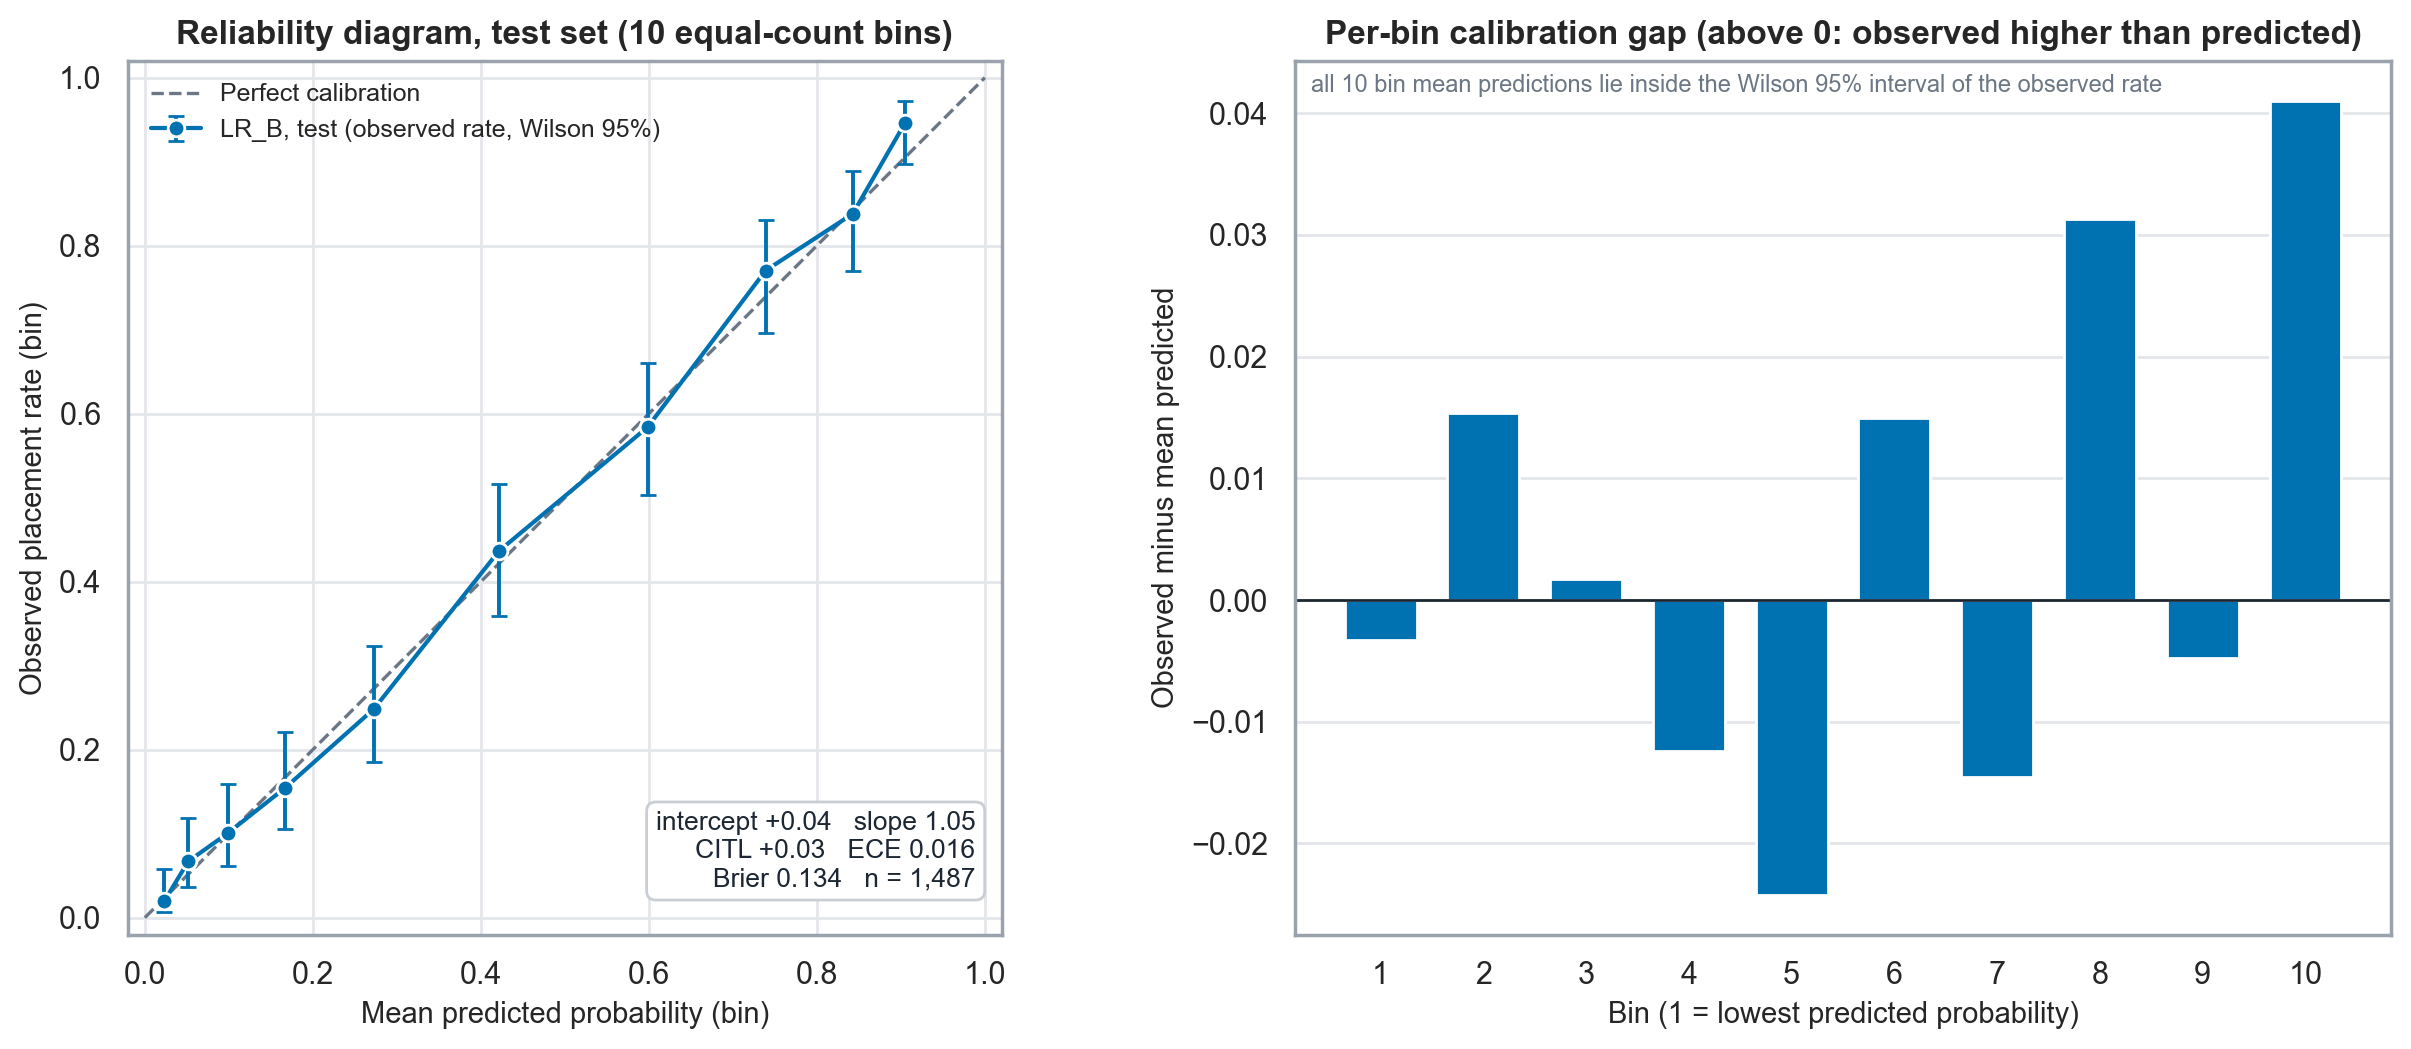

In [13]:
bins = quantile_bins(proba["LR_B"], y_te); bins.insert(0, "model", "LR_B")
bins[["model", "bin", "n", "p_min", "p_max", "mean_pred", "obs_rate", "calibration_gap", "ci_lo", "ci_hi"]].to_csv(MET / "08_test_calibration_bins.csv", index=False)
bins["gap_outside_wilson_ci"] = (bins.mean_pred < bins.ci_lo) | (bins.mean_pred > bins.ci_hi)
display(bins.rename(columns={"mean_pred": "mean_predicted"}).drop(columns="model").round(4).set_index("bin"))
print(f"bins whose mean prediction lies outside the Wilson 95% interval of the observed rate: {int(bins.gap_outside_wilson_ci.sum())} of {NB} (about 0.5 expected by chance if calibrated)")
print(f"max |gap| = {bins.calibration_gap.abs().max():.3f}; ECE = {lr['ece_quantile']:.4f} (perfect-calibration noise: mean {lr['ece_q_null_mean']:.4f}, 95th pct {lr['ece_q_null_p95']:.4f}); Brier = {lr['brier']:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12.8, 5.4), gridspec_kw={"width_ratios": [1.1, 1]})
ax = axes[0]; ax.plot([0, 1], [0, 1], color=NEUTRAL, ls="--", lw=1.2, label="Perfect calibration")
ax.errorbar(bins.mean_pred, bins.obs_rate, yerr=[bins.obs_rate - bins.ci_lo, bins.ci_hi - bins.obs_rate], fmt="o-", color=MODEL_COL["LR_B"], ecolor=MODEL_COL["LR_B"], elinewidth=1.4, capsize=3, ms=6, lw=1.5,
            markeredgecolor="white", label="LR_B, test (observed rate, Wilson 95%)")
ax.set_xlim(-0.02, 1.02); ax.set_ylim(-0.02, 1.02); ax.set_aspect("equal"); ax.set_xlabel("Mean predicted probability (bin)"); ax.set_ylabel("Observed placement rate (bin)")
ax.set_title("Reliability diagram, test set (10 equal-count bins)"); ax.legend(frameon=False, loc="upper left", fontsize=9)
ax.text(0.97, 0.05, f"intercept {lr['cal_intercept']:+.2f}   slope {lr['cal_slope']:.2f}\nCITL {lr['citl']:+.2f}   ECE {lr['ece_quantile']:.3f}\nBrier {lr['brier']:.3f}   n = {N_TE:,}",
        transform=ax.transAxes, ha="right", va="bottom", fontsize=9.5, color=INK, bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="#c9ced4"))
ax = axes[1]
ax.bar(bins.bin, -bins.calibration_gap, color=np.where(bins.gap_outside_wilson_ci, MODEL_COL["RF_B"], MODEL_COL["LR_B"]), width=0.7)
ax.axhline(0, color=INK, lw=1); ax.set_xticks(bins.bin); ax.set_xlabel("Bin (1 = lowest predicted probability)"); ax.set_ylabel("Observed minus mean predicted")
ax.set_title("Per-bin calibration gap (above 0: observed higher than predicted)"); ax.grid(axis="x", visible=False)
note = ("orange bar: mean prediction outside the Wilson 95% interval" if bins.gap_outside_wilson_ci.any()
        else f"all {NB} bin mean predictions lie inside the Wilson 95% interval of the observed rate")
ax.text(0.015, 0.985, note, transform=ax.transAxes, ha="left", va="top", fontsize=8.5, color=NEUTRAL)
savefig(fig, "phase7_test_reliability")

# PART D - Test probability distribution of `LR_B`
Compared descriptively with the Phase 5 out-of-fold training distribution (a different data set; differences are not treated as deterioration without evidence).

,Phase 7 test (refit model),Phase 5 train OOF
minimum,0.0071,0.0046
maximum,0.9415,0.9486
mean,0.4111,NaN
median,0.3342,0.3486
Q1,0.0997,0.0973
Q3,0.7395,0.7483
share below 0.20,0.3894,0.3894
share 0.20-0.80,0.4196,0.4024
share above 0.80,0.1910,0.2081
observed placed rate | p < 0.20,0.0812,0.0840


Extreme groups on test: p < 0.20: n = 579 (38.9%), observed placed rate 0.081 (mean predicted 0.082); p > 0.80: n = 284 (19.1%), observed placed rate 0.905 (mean predicted 0.877); middle band: n = 624 (42.0%), observed 0.503


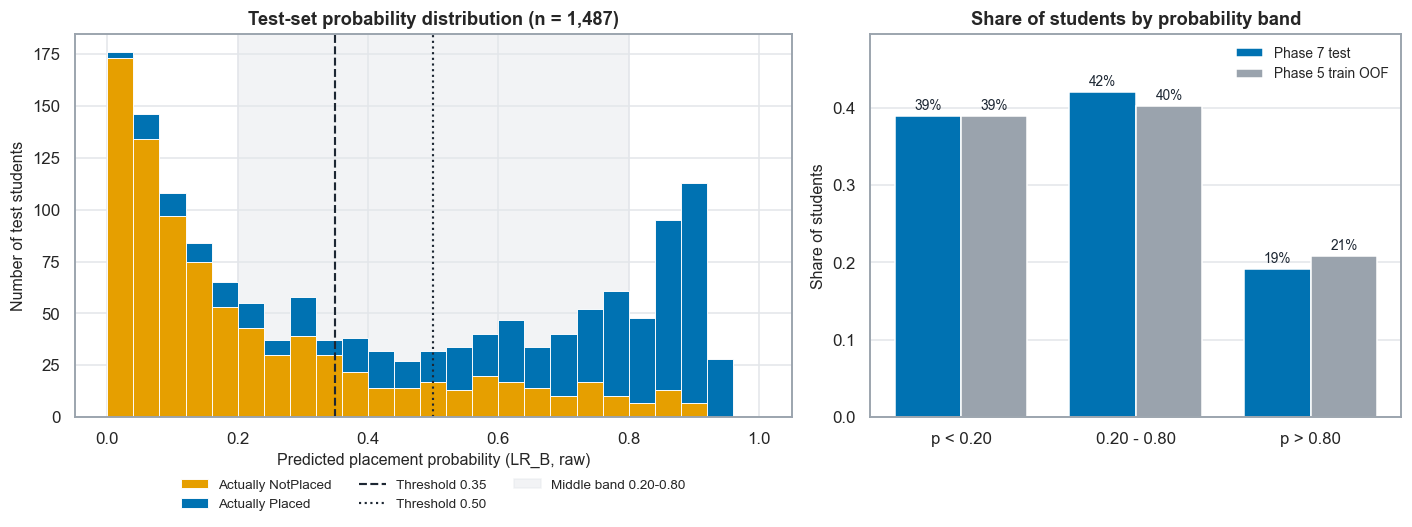

In [14]:
p = proba["LR_B"]; q1, med, q3 = np.percentile(p, [25, 50, 75])
lo_m, mid_m, hi_m = p < 0.2, (p >= 0.2) & (p <= 0.8), p > 0.8
dist = {"min": p.min(), "max": p.max(), "mean": p.mean(), "median": med, "q1": q1, "q3": q3,
        "share_below_0.2": lo_m.mean(), "share_0.2_to_0.8": mid_m.mean(), "share_above_0.8": hi_m.mean(),
        "n_below_0.2": int(lo_m.sum()), "n_0.2_to_0.8": int(mid_m.sum()), "n_above_0.8": int(hi_m.sum()),
        "observed_rate_below_0.2": y_te[lo_m].mean(), "observed_rate_0.2_to_0.8": y_te[mid_m].mean(), "observed_rate_above_0.8": y_te[hi_m].mean(),
        "mean_pred_below_0.2": p[lo_m].mean(), "mean_pred_0.2_to_0.8": p[mid_m].mean(), "mean_pred_above_0.8": p[hi_m].mean()}
pd.DataFrame([{"model": "LR_B", **dist}]).to_csv(MET / "08_test_probability_distribution_summary.csv", index=False)
p5 = pd.read_csv(PHASE_RESULTS / "06_probability_distribution_summary.csv"); p5 = p5[p5.model_id == "LR_B"].iloc[0]
tab = pd.DataFrame({"Phase 7 test (refit model)": [dist["min"], dist["max"], dist["mean"], dist["median"], dist["q1"], dist["q3"], dist["share_below_0.2"], dist["share_0.2_to_0.8"], dist["share_above_0.8"],
                                                    dist["observed_rate_below_0.2"], dist["observed_rate_above_0.8"]],
                    "Phase 5 train OOF": [p5["min"], p5["max"], np.nan, p5.q50, p5.q25, p5.q75, p5["share_below_0.2"], p5["share_0.2_to_0.8"], p5["share_above_0.8"],
                                          p5["observed_rate_below_0.2"], p5["observed_rate_above_0.8"]]},
                   index=["minimum", "maximum", "mean", "median", "Q1", "Q3", "share below 0.20", "share 0.20-0.80", "share above 0.80", "observed placed rate | p < 0.20", "observed placed rate | p > 0.80"])
display(tab.round(4))
print(f"Extreme groups on test: p < 0.20: n = {dist['n_below_0.2']} ({dist['share_below_0.2']:.1%}), observed placed rate {dist['observed_rate_below_0.2']:.3f} (mean predicted {dist['mean_pred_below_0.2']:.3f}); "
      f"p > 0.80: n = {dist['n_above_0.8']} ({dist['share_above_0.8']:.1%}), observed placed rate {dist['observed_rate_above_0.8']:.3f} (mean predicted {dist['mean_pred_above_0.8']:.3f}); "
      f"middle band: n = {dist['n_0.2_to_0.8']} ({dist['share_0.2_to_0.8']:.1%}), observed {dist['observed_rate_0.2_to_0.8']:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5.0), gridspec_kw={"width_ratios": [1.35, 1]})
ax = axes[0]; edges = np.linspace(0, 1, 26)
ax.hist([p[y_te == 0], p[y_te == 1]], bins=edges, stacked=True, color=["#E69F00", "#0072B2"], edgecolor="white", linewidth=0.6, label=["Actually NotPlaced", "Actually Placed"])
for x, ls, lab in [(0.35, "--", "Threshold 0.35"), (0.50, ":", "Threshold 0.50")]: ax.axvline(x, color=INK, ls=ls, lw=1.4, label=lab)
ax.axvspan(0.2, 0.8, color="#e3e6ea", alpha=0.45, zorder=0, label="Middle band 0.20-0.80")
ax.set_xlabel("Predicted placement probability (LR_B, raw)"); ax.set_ylabel("Number of test students"); ax.set_title(f"Test-set probability distribution (n = {N_TE:,})"); ax.legend(frameon=False, fontsize=8.8, loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=3)
ax = axes[1]; xb = np.arange(3); w = 0.38
v7 = [dist["share_below_0.2"], dist["share_0.2_to_0.8"], dist["share_above_0.8"]]; v5 = [p5["share_below_0.2"], p5["share_0.2_to_0.8"], p5["share_above_0.8"]]
b7 = ax.bar(xb - w / 2, v7, w, color="#0072B2", label="Phase 7 test"); b5 = ax.bar(xb + w / 2, v5, w, color="#9aa3ad", label="Phase 5 train OOF")
for bars in (b7, b5):
    for r in bars: ax.text(r.get_x() + r.get_width() / 2, r.get_height() + 0.008, f"{r.get_height():.0%}", ha="center", fontsize=9, color=INK)
ax.set_xticks(xb); ax.set_xticklabels(["p < 0.20", "0.20 - 0.80", "p > 0.80"]); ax.set_ylabel("Share of students"); ax.set_ylim(0, max(v7 + v5) * 1.18); ax.grid(axis="x", visible=False)
ax.set_title("Share of students by probability band"); ax.legend(frameon=False, fontsize=9)
savefig(fig, "phase7_test_probability_distribution")

# PART E - Development vs test comparison (LR_B)
Development numbers are read from the saved Phase 4/5 result files (not retyped). **Different models and data are compared**: Phase 5 CV and Phase 4 validation come from models fitted on train (or 80% of it); the Phase 7 test number comes from the refit on train + validation. The CV fold standard deviation (folds of about 1,390 students, similar to the test size of 1,487) is a rough yardstick for single-split sampling variation. The validation split also informed model selection, so its numbers are slightly optimistic.

In [15]:
cv = pd.read_csv(PHASE_RESULTS / "06_cv_summary.csv"); cv = cv[cv.model_id == "LR_B"].set_index("metric")
v4 = pd.read_csv(PHASE_RESULTS / "05_validation_results.csv").set_index("model_id").loc["LR_B"]
cm5 = pd.read_csv(PHASE_RESULTS / "06_calibration_metrics.csv"); cm5 = cm5[(cm5.model_id == "LR_B") & (cm5.method == "original")].set_index("dataset").loc["train_nested_CV"]
vc = pd.read_csv(PHASE_RESULTS / "06_validation_confirmation.csv"); vc = vc[(vc.model_id == "LR_B") & (vc.method == "original")].iloc[0]
cit = ci[(ci.model == "LR_B") & (ci.threshold == "")].set_index("metric")
dvt = pd.DataFrame([
    {"source": "Phase 5 train 5-fold CV (mean over folds)", "model_fitted_on": "80% of train per fold", "n": 6938, "roc_auc": cv.loc["roc_auc", "mean"], "log_loss": cv.loc["log_loss", "mean"], "brier": cv.loc["brier", "mean"],
     "roc_auc_sd_or_ci": f"fold SD {cv.loc['roc_auc', 'sd']:.4f}", "log_loss_sd_or_ci": f"fold SD {cv.loc['log_loss', 'sd']:.4f}", "brier_sd_or_ci": f"fold SD {cv.loc['brier', 'sd']:.4f}",
     "cal_slope": cm5.cal_slope, "cal_intercept": cm5.cal_intercept, "ece_quantile": cm5.ece_quantile},
    {"source": "Phase 4 validation (single split)", "model_fitted_on": "train", "n": 1487, "roc_auc": v4.roc_auc, "log_loss": v4.log_loss, "brier": v4.brier,
     "roc_auc_sd_or_ci": f"95% CI {v4.auc_ci_lo:.3f}-{v4.auc_ci_hi:.3f}", "log_loss_sd_or_ci": f"95% CI {v4.ll_ci_lo:.3f}-{v4.ll_ci_hi:.3f}", "brier_sd_or_ci": f"95% CI {v4.brier_ci_lo:.3f}-{v4.brier_ci_hi:.3f}",
     "cal_slope": vc.cal_slope, "cal_intercept": vc.cal_intercept, "ece_quantile": vc.ece_quantile},
    {"source": "Phase 7 TEST (single split, final model)", "model_fitted_on": "train + validation", "n": N_TE, "roc_auc": lr["roc_auc"], "log_loss": lr["log_loss"], "brier": lr["brier"],
     "roc_auc_sd_or_ci": f"95% CI {cit.loc['roc_auc', 'lower_95']:.3f}-{cit.loc['roc_auc', 'upper_95']:.3f}", "log_loss_sd_or_ci": f"95% CI {cit.loc['log_loss', 'lower_95']:.3f}-{cit.loc['log_loss', 'upper_95']:.3f}",
     "brier_sd_or_ci": f"95% CI {cit.loc['brier', 'lower_95']:.3f}-{cit.loc['brier', 'upper_95']:.3f}", "cal_slope": lr["cal_slope"], "cal_intercept": lr["cal_intercept"], "ece_quantile": lr["ece_quantile"]}])
dvt.to_csv(MET / "08_development_vs_test.csv", index=False)
display(dvt.round(4).set_index("source").T)
print("Test minus Phase 5 CV mean, in units of the CV fold SD (positive AUC = better; positive log loss / Brier = worse):")
for k in ("roc_auc", "log_loss", "brier"): print(f"  {k:9s}: {lr[k] - cv.loc[k, 'mean']:+.4f}  = {(lr[k] - cv.loc[k, 'mean']) / cv.loc[k, 'sd']:+.2f} fold SD;  test minus validation: {lr[k] - v4[k]:+.4f}")
print("Does the test 95% bootstrap interval contain the Phase 5 CV mean / the Phase 4 validation value?")
for k in ("roc_auc", "log_loss", "brier"):
    lo_, hi_ = cit.loc[k, "lower_95"], cit.loc[k, "upper_95"]; print(f"  {k:9s}: CV mean {lo_ <= cv.loc[k, 'mean'] <= hi_}, validation {lo_ <= v4[k] <= hi_}")

source,Phase 5 train 5-fold CV (mean over folds),Phase 4 validation (single split),"Phase 7 TEST (single split, final model)"
model_fitted_on,80% of train per fold,train,train + validation
n,6938,1487,1487
roc_auc,0.879,0.8717,0.8857
log_loss,0.4309,0.4408,0.4196
brier,0.1392,0.1409,0.1335
roc_auc_sd_or_ci,fold SD 0.0095,95% CI 0.854-0.890,95% CI 0.868-0.902
log_loss_sd_or_ci,fold SD 0.0157,95% CI 0.412-0.470,95% CI 0.393-0.449
brier_sd_or_ci,fold SD 0.0059,95% CI 0.130-0.152,95% CI 0.124-0.145
cal_slope,0.9902,0.9793,1.0513
cal_intercept,-0.0017,0.0393,0.0411


Test minus Phase 5 CV mean, in units of the CV fold SD (positive AUC = better; positive log loss / Brier = worse):
  roc_auc  : +0.0067  = +0.70 fold SD;  test minus validation: +0.0139
  log_loss : -0.0113  = -0.72 fold SD;  test minus validation: -0.0212
  brier    : -0.0057  = -0.97 fold SD;  test minus validation: -0.0074
Does the test 95% bootstrap interval contain the Phase 5 CV mean / the Phase 4 validation value?
  roc_auc  : CV mean True, validation True
  log_loss : CV mean True, validation True
  brier    : CV mean True, validation True


# PART F - Secondary models (descriptive only)
`GB_B` and `RF_B` are evaluated on the identical test set, frozen configurations, refitted on train + validation. They are **not** used to select or replace the primary model.

In [16]:
rows = []
for m in MODEL_IDS:
    r = {"model": m, "model_name": MODEL_NAME[m], "roc_auc": cal[m]["roc_auc"], "log_loss": cal[m]["log_loss"], "brier": cal[m]["brier"],
         "roc_auc_lo95": ci[(ci.model == m) & (ci.metric == "roc_auc")].lower_95.iloc[0], "roc_auc_hi95": ci[(ci.model == m) & (ci.metric == "roc_auc")].upper_95.iloc[0],
         "log_loss_lo95": ci[(ci.model == m) & (ci.metric == "log_loss")].lower_95.iloc[0], "log_loss_hi95": ci[(ci.model == m) & (ci.metric == "log_loss")].upper_95.iloc[0],
         "brier_lo95": ci[(ci.model == m) & (ci.metric == "brier")].lower_95.iloc[0], "brier_hi95": ci[(ci.model == m) & (ci.metric == "brier")].upper_95.iloc[0],
         "f1_at_0.50": class_metrics(y_te, proba[m], 0.50)["f1"], "f1_at_0.35": class_metrics(y_te, proba[m], T_SEL)["f1"],
         "cal_slope": cal[m]["cal_slope"], "cal_intercept": cal[m]["cal_intercept"], "ece_quantile": cal[m]["ece_quantile"], "role": "primary (frozen)" if m == "LR_B" else "secondary comparator (frozen)"}
    rows.append(r)
mc = pd.DataFrame(rows); mc.to_csv(MET / "08_final_model_comparison.csv", index=False)
display(mc[["model", "roc_auc", "log_loss", "brier", "f1_at_0.50", "f1_at_0.35", "cal_slope", "ece_quantile"]].round(4).set_index("model"))
sec = cls[cls.model.isin(["GB_B", "RF_B"])][["model", "threshold", "accuracy", "precision", "recall", "f1", "specificity", "sensitivity", "TP", "TN", "FP", "FN"]]
print("Secondary models, classification metrics at the two frozen thresholds:"); display(sec.round(4).set_index(["model", "threshold"]))
print("Paired bootstrap differences, LR_B minus comparator (intervals including 0 = no distinguishable difference):")
display(ci[ci.model.str.contains("paired")][["model", "metric", "estimate", "lower_95", "upper_95"]].round(4).reset_index(drop=True))

,roc_auc,log_loss,brier,f1_at_0.50,f1_at_0.35,cal_slope,ece_quantile
model,,,,,,,
LR_B,0.8857,0.4196,0.1335,0.7722,0.7810,1.0513,0.0164
GB_B,0.8858,0.4186,0.1340,0.7515,0.7775,1.0565,0.0314
RF_B,0.8859,0.4204,0.1347,0.7561,0.7775,1.1500,0.0241


Secondary models, classification metrics at the two frozen thresholds:


accuracy  precision  recall      f1  specificity  sensitivity   TP   TN   FP   FN
model threshold                                                                                   
GB_B  0.50         0.8003     0.7782  0.7265  0.7515       0.8527       0.7265  449  741  128  169
      0.35         0.8003     0.7238  0.8398  0.7775       0.7722       0.8398  519  671  198   99
RF_B  0.50         0.8056     0.7901  0.7249  0.7561       0.8631       0.7249  448  750  119  170
      0.35         0.7949     0.7078  0.8625  0.7775       0.7468       0.8625  533  649  220   85

Paired bootstrap differences, LR_B minus comparator (intervals including 0 = no distinguishable difference):


,model,metric,estimate,lower_95,upper_95
0,LR_B minus GB_B (paired),roc_auc,-0.0001,-0.0033,0.0030
1,LR_B minus GB_B (paired),log_loss,0.0010,-0.0044,0.0064
2,LR_B minus GB_B (paired),brier,-0.0004,-0.0025,0.0016
3,LR_B minus RF_B (paired),roc_auc,-0.0002,-0.0042,0.0036
4,LR_B minus RF_B (paired),log_loss,-0.0008,-0.0074,0.0067
5,LR_B minus RF_B (paired),brier,-0.0011,-0.0036,0.0014


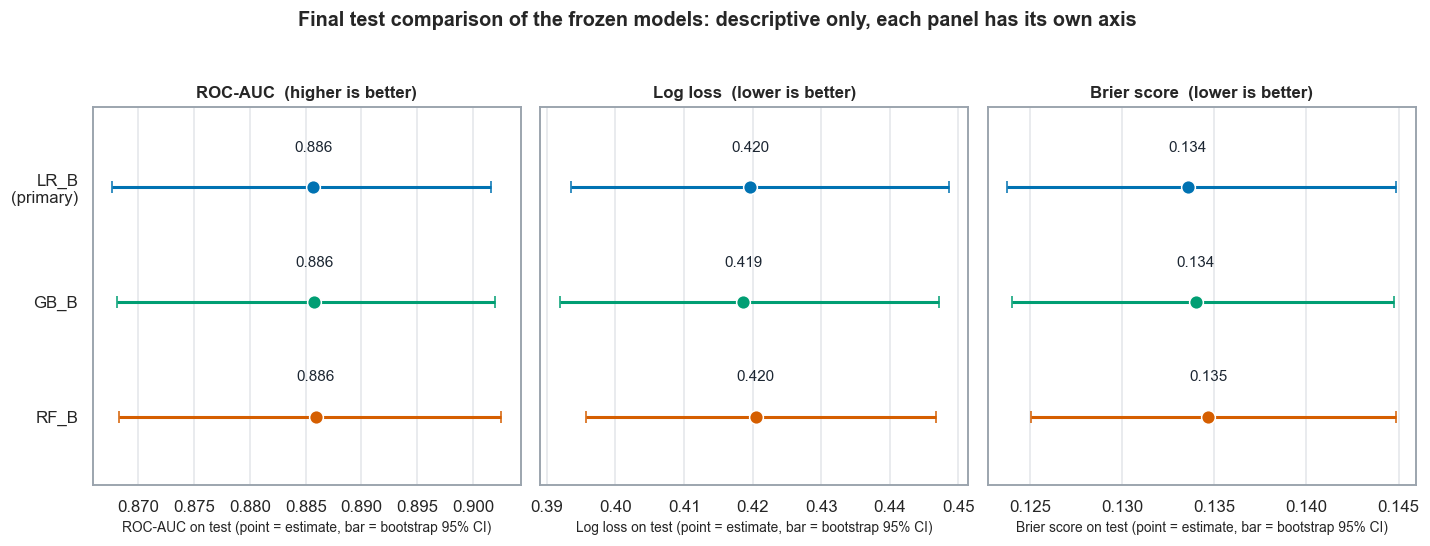

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(13.2, 4.8))
for ax, (k, ttl, better) in zip(axes, [("roc_auc", "ROC-AUC", "higher is better"), ("log_loss", "Log loss", "lower is better"), ("brier", "Brier score", "lower is better")]):
    for i, m in enumerate(MODEL_IDS):
        r = mc[mc.model == m].iloc[0]
        ax.errorbar(r[k], i, xerr=[[r[k] - r[f"{k}_lo95"]], [r[f"{k}_hi95"] - r[k]]], fmt="o", color=MODEL_COL[m], ecolor=MODEL_COL[m], elinewidth=2, capsize=4, ms=9, markeredgecolor="white")
        ax.text(r[k], i - 0.28, f"{r[k]:.3f}", ha="center", va="bottom", fontsize=10, color=INK)
    ax.set_yticks(range(3)); ax.set_yticklabels(["LR_B\n(primary)", "GB_B", "RF_B"] if ax is axes[0] else [""] * 3); ax.set_ylim(2.6, -0.7); ax.grid(axis="y", visible=False)
    ax.set_title(f"{ttl}  ({better})", fontsize=11); ax.set_xlabel(f"{ttl} on test (point = estimate, bar = bootstrap 95% CI)", fontsize=9)
fig.suptitle("Final test comparison of the frozen models: descriptive only, each panel has its own axis", y=1.03, fontsize=13, fontweight="semibold")
savefig(fig, "phase7_final_model_comparison")

# PART G - Confusion matrices (LR_B), identical conventions
Rows = actual class, columns = predicted class; cell colour = share of the actual class (same 0-1 scale in both figures); text = count and share.

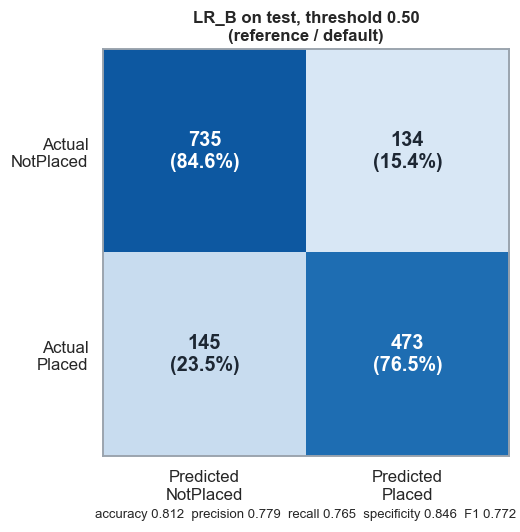

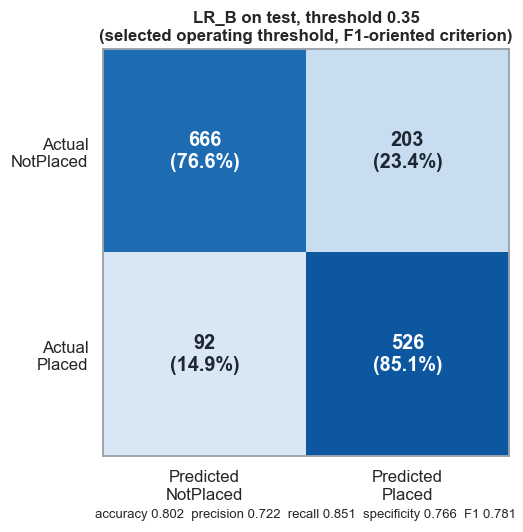

In [18]:
for t, tag in [(0.50, "050"), (0.35, "035")]:
    r = class_metrics(y_te, proba["LR_B"], t); cmx = np.array([[r["TN"], r["FP"]], [r["FN"], r["TP"]]])
    fig, ax = plt.subplots(figsize=(5.6, 5.0)); share = cmx / cmx.sum(1, keepdims=True)
    ax.imshow(share, cmap="Blues", vmin=0, vmax=1)
    for (a_, b_), v in np.ndenumerate(cmx): ax.text(b_, a_, f"{v:,}\n({share[a_, b_]:.1%})", ha="center", va="center", fontsize=13, fontweight="semibold", color="white" if share[a_, b_] > 0.55 else INK)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Predicted\nNotPlaced", "Predicted\nPlaced"]); ax.set_yticks([0, 1]); ax.set_yticklabels(["Actual\nNotPlaced", "Actual\nPlaced"]); ax.grid(False)
    tl = "reference / default" if t == 0.50 else "selected operating threshold, F1-oriented criterion"
    ax.set_title(f"LR_B on test, threshold {t:.2f}\n({tl})", fontsize=11)
    ax.set_xlabel(f"accuracy {r['accuracy']:.3f}  precision {r['precision']:.3f}  recall {r['recall']:.3f}  specificity {r['specificity']:.3f}  F1 {r['f1']:.3f}", fontsize=8.6)
    savefig(fig, f"phase7_confusion_matrix_{tag}")

## Phase 7 conclusions

<!--PHASE7_FINDINGS-->
> **Evidence labels.** *Development evidence* = Phases 1-6 (train, validation, cross-validation; unchanged by this phase). *Final test evidence* = Phase 7: **one** evaluation of the frozen model on the held-out test split (n = 1,487; observed placement rate 41.56%, 618 Placed / 869 NotPlaced). No modelling decision below was changed after the test set was opened (see the access history that follows). All statements are about association and prediction in one observational, possibly rule-generated dataset; none is causal. 95% intervals are percentile bootstrap intervals (2,000 resamples of test students, seed 42).

> **Test-set access history (disclosed, not hidden).** Test data were not used for model development, selection, tuning, calibration, or threshold selection. Earlier exploratory work accessed the eventual test rows descriptively: the Phase 1-3 notebooks (data understanding and split construction, EDA, statistical analysis) loaded the full data, including the rows later assigned to the test split, for descriptive and split-sanity analyses; no predictive model was fitted or evaluated on those rows. Before the gated Phase 7 evaluation, two orientation shell commands also read `data/processed/test.csv` outside the audit hook (`head -2`, which displayed the header and one data row, and `wc -l data/processed/*.csv`, line counts only); neither was used for any model decision, tuning, threshold selection, calibration or fitting. The audit hooks in the Phase 4-6 notebooks show that *those notebooks* did not open the test files; that describes those notebooks, not the whole project history. During Phase 7 the test set was intentionally accessed once, under the final-evaluation audit gate, after the modelling protocol had been frozen.

## A. Final model
**Frozen specification (recorded in `results/metrics/modeling/08_frozen_protocol.json` before the test set was opened).**
- **Primary model: Logistic Regression B (`LR_B`)** - CGPA, AptitudeTestScore, SoftSkillsRating, SSC_Marks, HSC_Marks standardised; Internships, Projects, Workshops/Certifications one-hot categorical (reference levels 1, 3, 0); ExtracurricularActivities and PlacementTraining binary; L2, C = 1, **no class weighting**, **raw probabilities, no recalibration** (Phase 5: sigmoid negligible, isotonic not helpful, no method met the materiality rule).
- **Thresholds (both declared in advance):** **0.50** (reference / default) and **0.35** (the *selected operating threshold under the F1-oriented criterion*; Phase 6). No other threshold was evaluated on test and 0.35 is not called "the best" threshold.
- **Pre-declared secondary comparators:** `GB_B` and `RF_B` with their frozen Phase 4 configurations; not used to select or replace `LR_B`.

**Two distinct models.** The final Logistic Regression B specification was frozen before test access. After all model, calibration, and threshold decisions were complete, the same frozen specification was refit using the combined training + validation data and then evaluated once on the held-out test set. The CV and validation development results come from models fitted on train data only (the CV models on 80% of train); the final test metrics come from the frozen specification refit on train + validation. The test set was not used to make any subsequent modelling decision.
| | Phase 4/5/6 *development* model | Phase 7 *final* model |
|---|---|---|
| Specification | frozen pipeline above | identical (`sklearn.clone` of the Phase 4 pipeline; parameters asserted equal to Phase 4 and to `model_configs.json`) |
| Fitted on | train (6,938) | **train + validation (8,425)**, after every decision was frozen |
| Used for | validation, CV, calibration, threshold selection, explainability | test predictions only |

For each of the three models, a clone fitted on **train only** reproduced the saved Phase 4 validation probabilities (tolerance 1e-8), which shows that the clone is the Phase 4 specification and that the fit is deterministic; only then was the clone refitted on train + validation. Refitting re-estimates fitted quantities only: `StandardScaler` means moved by at most 0.02 and SDs by at most 0.05 (SSC_Marks SD 10.36 to 10.41) and the largest `LR_B` coefficient change was 0.111 log-odds (`Projects = 0`, which has about 19 training students and is not interpretable); every other coefficient moved by at most 0.058. No preprocessing, representation, hyper-parameter, feature, regularisation, calibration method or threshold changed. Models are saved in `models/phase7/`; Phase 4 artifacts are byte-identical (checked by SHA-256 at the start and end of the run).

## B. Test discrimination (LR_B)
| Metric | Estimate | 95% bootstrap CI |
|---|---|---|
| **ROC-AUC** | **0.886** (0.8857) | 0.868 - 0.902 |
| Log loss | 0.420 (0.4196) | 0.394 - 0.449 |
| Brier | 0.134 (0.1335) | 0.124 - 0.145 |

A randomly chosen Placed test student receives a higher predicted probability than a randomly chosen NotPlaced one about 89% of the time. Reference values (Phase 4): always predicting the training rate gives AUC 0.500, log loss 0.679, Brier 0.243.

## C. Probability quality and calibration (LR_B, raw probabilities, test)
| Quantity | Value | Reading |
|---|---|---|
| Calibration slope (joint fit) | **1.051** (0.951-1.152) | compatible with 1 |
| Calibration intercept (joint fit) | +0.041 (-0.099 to +0.181) | compatible with 0 |
| Calibration-in-the-large (slope fixed at 1) | +0.032 (-0.104 to +0.169) | mean prediction 0.411 vs observed 0.416 |
| ECE (10 equal-count bins) | **0.016** | at or below the noise expected under *perfect* calibration (mean 0.023, 95th percentile 0.034) |
| ECE (10 equal-width bins, sensitivity) | 0.017 | |

- **Reliability diagram** (`phase7_test_reliability.png`, `08_test_calibration_bins.csv`; 10 equal-count bins of 148-149 students): the largest per-bin gap is 0.041 (top decile: mean predicted 0.905, observed 0.946); the next largest are 0.031 (bin 8: 0.739 vs 0.770), 0.024 (bin 5: 0.273 vs 0.248) and 0.015 (bin 2). **No bin's mean prediction falls outside its Wilson 95% interval.** (Gap in the CSV = mean predicted minus observed; positive = over-prediction.)
- The one visible regularity is mild **under-prediction at the top** (observed above predicted by about 4 points in the top decile and 3 points in decile 8, while decile 9 is on the diagonal; students with p > 0.80 are placed 90.5% of the time against a mean prediction of 87.7%). The same pattern was seen in Phase 5 (top decile 0.909 predicted vs 0.949 observed), so it is a consistent small feature of the model rather than a test-only surprise. It is within sampling noise on this sample size and **no recalibration was applied or tested**; it is reported as a limitation.
- Probabilities are therefore acceptably calibrated on test, in line with Phase 5. As in Phase 5, a probability describes a **group** of similar students (for example decile 9: mean prediction 0.843, observed placement rate 0.838), not a guarantee for an individual.

**Probability distribution (LR_B, test; `08_test_probability_distribution_summary.csv`, `phase7_test_probability_distribution.png`).**
| | Test (refit model) | Phase 5 train OOF |
|---|---|---|
| Minimum / maximum | 0.007 / 0.942 | 0.005 / 0.949 |
| Mean / median | 0.411 / 0.334 | - / 0.349 |
| Q1 / Q3 | 0.100 / 0.740 | 0.097 / 0.748 |
| Share below 0.20 | 38.9% (n = 579) | 38.9% |
| Share 0.20 - 0.80 | 42.0% (n = 624) | 40.2% |
| Share above 0.80 | 19.1% (n = 284) | 20.8% |
| Observed placed rate, p < 0.20 | 8.1% (mean predicted 8.2%) | 8.4% |
| Observed placed rate, p > 0.80 | 90.5% (mean predicted 87.7%) | 89.5% |
| Observed placed rate, 0.20 - 0.80 | 50.3% | 48.8% |

The two distributions are very similar; the differences (about 2 points per band) are small relative to sampling variation and are not read as deterioration. About 58% of test students fall in a confident band, and in both bands the observed rate is within about 3 points of the mean prediction. The middle band is placed about half the time, i.e. genuinely uncertain, as in Phase 5.

## D. Threshold 0.50 (reference / default), LR_B, test
| Accuracy | Precision | Recall = Sensitivity | F1 | Specificity | TP | TN | FP | FN |
|---|---|---|---|---|---|---|---|---|
| 0.812 (0.792-0.831) | 0.779 (0.746-0.811) | 0.765 (0.732-0.797) | 0.772 (0.744-0.797) | 0.846 (0.821-0.869) | 473 | 735 | 134 | 145 |

The model labels 40.8% of test students "Placed" against a true rate of 41.6%.

## E. Threshold 0.35 (selected operating threshold under the F1-oriented criterion), LR_B, test
| Accuracy | Precision | Recall = Sensitivity | F1 | Specificity | TP | TN | FP | FN |
|---|---|---|---|---|---|---|---|---|
| 0.802 (0.781-0.820) | 0.722 (0.689-0.754) | 0.851 (0.822-0.878) | 0.781 (0.756-0.804) | 0.766 (0.737-0.793) | 526 | 666 | 203 | 92 |

The model labels 49.0% of test students "Placed".

**Threshold comparison (LR_B; only the two pre-declared thresholds were evaluated).**
| Threshold | Accuracy | Precision | Recall | F1 | Specificity | Sensitivity |
|---|---:|---:|---:|---:|---:|---:|
| 0.50 | 0.812 | 0.779 | 0.765 | 0.772 | 0.846 | 0.765 |
| 0.35 | 0.802 | 0.722 | 0.851 | 0.781 | 0.766 | 0.851 |

**Trade-off.** Lowering the threshold from 0.50 to 0.35 converts 53 false negatives into 69 additional false positives: recall rises by 8.6 points (0.765 to 0.851), precision falls by 5.7 points, specificity falls by 8.0 points, accuracy by 1.1 points, and F1 differs by only 0.009 (the F1 intervals overlap almost completely; no paired interval for the F1 difference was computed, so no difference in F1 is claimed). On the final test set, the 0.35 threshold produced higher recall and F1 than 0.50, while also producing lower precision and specificity (0.35 was selected in Phase 6 by the predeclared validation F1-oriented rule; 0.50 is retained as the conventional reference threshold). This reproduces the Phase 6 picture: 0.35 favours recall, 0.50 is the more conservative positive-classification rule. **Neither threshold is universally preferable**: the right choice depends on the relative cost of a false "likely placed" versus a missed placed student, which this project has not defined. The probability, not the label, remains the primary output.

## F. Secondary models (descriptive only; frozen Phase 4 configurations refitted on train + validation)
| Model | ROC-AUC (95% CI) | Log loss | Brier | F1 @ 0.50 | F1 @ 0.35 | Calibration slope | ECE |
|---|---|---|---|---|---|---|---|
| **LR_B (primary)** | 0.886 (0.868-0.902) | 0.420 | 0.134 | 0.772 | 0.781 | 1.05 | 0.016 |
| GB_B | 0.886 (0.868-0.902) | 0.419 | 0.134 | 0.752 | 0.778 | 1.06 | 0.031 |
| RF_B | 0.886 (0.868-0.902) | 0.420 | 0.135 | 0.756 | 0.778 | 1.15 | 0.024 |

| Paired bootstrap difference (LR_B minus other) | ROC-AUC | Log loss | Brier |
|---|---|---|---|
| vs GB_B | -0.000 (-0.003, +0.003) | +0.001 (-0.004, +0.006) | -0.000 (-0.003, +0.002) |
| vs RF_B | -0.000 (-0.004, +0.004) | -0.001 (-0.007, +0.007) | -0.001 (-0.004, +0.001) |

- On the three primary metrics the three models are **indistinguishable** on test (AUC 0.8857-0.8859; log loss 0.4186-0.4204; Brier 0.1335-0.1347; every paired interval includes 0), which continues the Phase 4/5 tie. At 0.50, `GB_B` and `RF_B` have lower recall (0.727 / 0.725 vs 0.765) at similar precision, hence lower F1 (0.752 / 0.756 vs 0.772); at 0.35 all three have F1 about 0.78. These F1 differences were not tested and are descriptive. `RF_B` again has a calibration slope above 1 (1.15: probabilities slightly too moderate), as in Phase 5 (1.08).
- **No model is declared superior from these numbers, and `LR_B` is not replaced.** The primary model was frozen before the test set was opened; test differences this small are within sampling noise.

## G. Development vs test (LR_B)
| | Phase 5 train 5-fold CV (mean; fold SD) | Phase 4 validation (single split, train-only model) | Phase 7 TEST (single split, train + validation model) |
|---|---|---|---|
| ROC-AUC | 0.879 (SD 0.0095) | 0.872 (0.854-0.890) | **0.886** (0.868-0.902) |
| Log loss | 0.431 (SD 0.0157) | 0.441 (0.412-0.470) | **0.420** (0.394-0.449) |
| Brier | 0.139 (SD 0.0059) | 0.141 (0.130-0.152) | **0.134** (0.124-0.145) |
| Calibration slope / intercept | 0.99 / -0.002 | 0.98 / +0.039 | 1.05 / +0.041 |
| ECE (10 equal-count bins) | 0.021 | 0.024 | 0.016 |

(`results/metrics/modeling/08_development_vs_test.csv`; the development numbers are read from the saved Phase 4/5 files.)

- **Broadly consistent with the development estimates.** Test metrics fall within approximately one CV standard deviation of the corresponding CV means. Test AUC is 0.007 above the CV mean (0.7 fold SDs) and 0.014 above validation; test log loss and Brier are slightly *better* than both development estimates (0.7 and 1.0 fold SDs). The test 95% intervals contain both the CV mean and the validation value for all three metrics. Fold SDs (folds of about 1,390 students) are a rough yardstick for single-split sampling variation at the test size (1,487), so all differences are of the size expected from sampling alone.
- **Reading the higher test performance.** It does not by itself establish improved generalisation and may reflect sampling variation and the larger train + validation refit. The comparison cannot separate a lucky or easy test split from the 21% extra training data of the refit model (a small gain is plausible for a 15-parameter model), and the validation split's slight optimism (it informed Phase 4 selection) is not clearly visible either. The honest reading is "consistent with the development estimates", not "the model is better than expected".
- **Calibration remains reasonable**: slope and intercept compatible with 1 and 0, ECE below its noise yardstick, as in development. The small top-end under-prediction persists (Section C).
- Nothing here is labelled overfitting: the differences are not evidence of it, and the development-phase train-validation gaps (Phase 4) were small for LR_B.

## H. Limitations
- **Dataset.** One dataset, one split, 1,487 test students: intervals are about +/-0.017 for AUC and +/-0.02 for accuracy. Phase 2 found 8 conflicting-label profiles in the top region; error rates near 20% at 0.50 are consistent with a performance ceiling for these ten features (Phase 6).
- **Possible constructed / rule-like structure.** The observed structure (bounded scores with hard floors and ceilings, step-like and non-monotonic count effects, very strong associations, a model-family tie, conflicting labels) is **consistent with a rule-based or constructed dataset, although this is not established by the dataset source.** **Strong performance on this dataset does not establish equivalent performance on real-world university placement populations, other campuses or other years.**
- **Validation-selection optimism.** Model, representation and threshold were chosen on validation (and Phase 3 EDA informed the categorical-count representation), so development figures at the chosen settings are slightly optimistic; the test split is the independent check, but it is a single sample.
- **Test rows in earlier descriptive phases.** The Phase 1-3 notebooks loaded the full data, including the rows later assigned to the test split (notebooks 03 and 04 also loaded `modeling_dataset.csv` and `test.csv` for descriptive and split-sanity analyses; disclosed in notebook 05). No predictive model was fitted or evaluated on test rows before Phase 7, but the descriptive analyses that motivated treating counts as categories included test rows, so test independence is not absolute. The Phase 4-6 audit hooks describe those notebooks only, not the whole project history.
- **Threshold dependence.** Classification metrics depend on the threshold; 0.35 was selected under an F1 criterion that weights errors equally. The 0.35 vs 0.50 F1 difference is small relative to its interval; the costs of the two error types were never defined.
- **Refit vs development model.** Test results describe the train + validation refit; validation and CV numbers describe train-only models.
- **Calibration.** Small, consistent top-end under-prediction (about 3-4 points in deciles 8 and 10) was observed and deliberately not recalibrated.
- **Observational / non-causal.** Coefficients and importance describe associations learned by the model; they do not say that changing a feature (e.g. attending placement training) would change an outcome.
- **Test-access disclosure (process deviation).** During orientation, before the notebook (and its audit hook) ran, two shell commands touched `data/processed/test.csv` outside the hook: `head -2` (displaying the header and the first data row) and `wc -l data/processed/*.csv` (line counts only; the count matches the documented 1,487 + header). Neither result was used in any decision (every decision was already frozen and recorded), but it means the notebook's hook attests only to what happened inside the notebook process.

## I. Final conclusion
**Decision.** No methodological problem occurred inside the pre-registered evaluation (single open, frozen specification asserted identical, no tuning after opening, processed/raw data and Phase 4 artifacts byte-identical). **For this dataset and experimental protocol, Logistic Regression B was retained as the final model.** It is final only in that sense: it is not claimed to be the best model in general, universally superior, or guaranteed to generalise, and it does not show that any feature causes placement.

**What the project can legitimately claim, based on the complete experiment.**
1. On this dataset, with a leakage-controlled split (duplicates collapsed, conflicting-label profiles excluded, zero profile overlap), a logistic regression on ten recorded variables, with the count variables treated as categories, ranks held-out students with ROC-AUC about 0.89 (95% interval 0.87-0.90), log loss 0.42 and Brier 0.134, against 0.50 / 0.68 / 0.24 for a base-rate predictor.
2. Its raw probabilities are acceptably calibrated (slope 1.05, ECE 0.016); no recalibration was needed, and the small top-end under-prediction is a stated limitation.
3. Gradient boosting and random forest give statistically indistinguishable test performance; the extra complexity bought nothing measurable, so the interpretable model was retained.
4. At the reference threshold 0.50 the model reaches accuracy 0.81, precision 0.78 and recall 0.77; at the pre-declared 0.35 it trades some precision for recall (0.72 / 0.85) with a slightly higher but not formally compared F1 (0.781 vs 0.772). Which is appropriate depends on costs the project has not defined.
5. Test performance was broadly consistent with the development estimates (within approximately one CV standard deviation of the CV means); the higher test performance does not by itself establish improved generalisation and may reflect sampling variation and the larger train + validation refit.
6. The associations the model uses (aptitude, placement training, extracurricular activities and the non-monotonic count variables dominate) are descriptive of this dataset and are not causal.

**What it cannot claim.** Equivalent performance on real placement populations (the dataset's structure is consistent with a constructed or rule-based origin, not established), individual-level certainty (about 20% of students are misclassified at 0.50 and some confident predictions are wrong), or that any threshold or any model is best in general.


# FINAL AUDIT

In [19]:
SNAP_END = snapshot()
assert SNAP_END == SNAP_START, {k: (SNAP_START[k], SNAP_END[k]) for k in SNAP_START if SNAP_START[k] != SNAP_END[k]}
TEST_STAT_END = {"processed_test": stat_only(PROC / "test.csv"), "raw_test": stat_only(RAW / "test.csv")}
assert TEST_STAT_END == TEST_STAT_START, "test-file size/mtime changed"
# (the test file is NOT hashed again - that would be a second read; the single-read SHA-256 is recorded in the access marker)
print("DATA: raw train/validation SHA-256 = Phase 1.5 originals; processed train, validation, modeling_dataset and Phase 4 model files byte-identical at start and end of this run;")
print("      raw and processed test files unchanged (size and mtime); the raw test file was not opened by this notebook.")

# models: frozen specifications unchanged
with open(MODELS / "model_configs.json", encoding="utf-8") as fh: P4_END = json.load(fh)
assert P4_END == P4
for m in MODEL_IDS:
    assert params_equal(final_models[m], dev_models[m]) and final_models[m].get_params()["model__random_state"] == 42
    for k, v in P4["models"][m]["config"].items(): assert final_models[m].get_params()[f"model__{k}"] == v
assert THRESHOLDS == [0.50, 0.35] and set(cls.threshold) == {0.50, 0.35} and set(cmp_thr.threshold) == {0.50, 0.35}
print("MODELS: LR_B, GB_B, RF_B specifications identical to Phase 4 (parameters asserted); thresholds 0.50 and 0.35 only; raw probabilities, no recalibration.")

if not DRY:
    for m in MODEL_IDS: joblib.dump(final_models[m], MOD7 / f"{m}_final.joblib")
    with open(MOD7 / "final_model_configs.json", "w", encoding="utf-8") as fh:
        json.dump({"fitted_on": "train + validation", "n": int(len(X_dev)), "specification_source": "models/phase4/model_configs.json (unchanged)", "models": {m: P4["models"][m] for m in MODEL_IDS},
                   "thresholds": THRESHOLDS, "sklearn_version": sklearn.__version__, "test_file_sha256": TEST_SHA}, fh, indent=2)
    print("Phase 7 final models saved to models/phase7/ (Phase 4 artifacts untouched).")

# test protocol
data_ext = (".csv", ".parquet", ".json", ".joblib", ".pkl", ".feather", ".xlsx")
opened = [os.path.normpath(p) for p in _OPENED if p.lower().endswith(data_ext)]
test_opens = [p for p in opened if os.path.basename(p).lower() == "test.csv"]
raw_test_opens = [p for p in opened if os.path.basename(p).lower() == "test.csv" and "raw" in [s.lower() for s in Path(p).parts]]
print("\nData files opened during this run (distinct):"); [print("  ", p) for p in sorted(set(opened))]
assert not raw_test_opens, "raw test file was opened"
assert (len(test_opens) == 1 and GATE["opens"] == 1) if not DRY else (len(test_opens) == 0 and GATE["opens"] == 0)
assert MARKER.exists() and json.loads(MARKER.read_text(encoding="utf-8"))["sha256"] == TEST_SHA
print(f"\nTEST PROTOCOL: processed test.csv opened {GATE['opens'] if not DRY else 'n/a (dry run)'} time(s) by this notebook, inside the gated cell; the raw test file was not opened by this notebook; access marker {MARKER.name} written.")
print("   No model selection, threshold search, calibration selection, feature selection, hyper-parameter tuning or preprocessing change was performed after the test set was opened:")
print("   thresholds, models and calibration status are the frozen values asserted above and recorded in 08_frozen_protocol.json (written before the open).")
print("\nTest data were not used for model development, selection, tuning, calibration, or threshold selection. Phases 1-3 accessed the eventual test rows descriptively; Phase 7 performed the final gated test evaluation only after the protocol was frozen.")

DATA: raw train/validation SHA-256 = Phase 1.5 originals; processed train, validation, modeling_dataset and Phase 4 model files byte-identical at start and end of this run;
      raw and processed test files unchanged (size and mtime); the raw test file was not opened by this notebook.
MODELS: LR_B, GB_B, RF_B specifications identical to Phase 4 (parameters asserted); thresholds 0.50 and 0.35 only; raw probabilities, no recalibration.


Phase 7 final models saved to models/phase7/ (Phase 4 artifacts untouched).

Data files opened during this run (distinct):
   C:\Users\Aryan\.matplotlib\fontlist-v390.json
   C:\Users\Aryan\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy-2.4.2.dist-info\direct_url.json
   D:\Student-Placement-Prediction\student-placement-prediction\data\processed\modeling_dataset.csv
   D:\Student-Placement-Prediction\student-placement-prediction\data\processed\test.csv
   D:\Student-Placement-Prediction\student-placement-prediction\data\processed\train.csv
   D:\Student-Placement-Prediction\student-placement-prediction\data\processed\validation.csv
   D:\Student-Placement-Prediction\student-placement-prediction\data\raw\train.csv
   D:\Student-Placement-Prediction\student-placement-prediction\data\raw\validation.csv
   D:\Student-Placement-Prediction\student-placement-prediction\models\phase4\GB_B.joblib
   D:\Student-Placement-Prediction\student-placement-prediction\models\phase4\LR_B